# Assignment 2 — Logistic Regression

**Machine Learning for Media Production | Small individual assignment (5 marks)**

**Submit:** Your completed `.ipynb` file with **all outputs shown**. Run cells in order before submitting. You do **not** need a separate report, LaTeX document, or slides.

**Save your completed notebook in:** `MLMPworkshop/assignment02_Logistic_Regression/` in your own GitHub repository. All five assignments should be kept in the same repository.

This assignment uses a **different synthetic dataset** from the Workshop 05 demonstration. Complete Tasks 1–5 below.

| Task | Marks |
|---|---:|
| 1. Understand the dataset | 1 |
| 2. Check a predicted probability and loss | 1 |
| 3. Compare classification thresholds | 1 |
| 4. Investigate one classification mistake | 1 |
| 5. AI-use and verification note | 1 |
| **Total** | **5** |

## Provided data and model — run without changing

There are two features and two classes. The data are **synthetic**; do not invent real-world meanings for the features. We train on `X_train` only and evaluate on `X_test`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

np.set_printoptions(precision=3, suppress=True)
X, y = make_classification(
    n_samples=150,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=0.85,
    flip_y=0.08,
    random_state=7,
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=11, stratify=y
)
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
probabilities = model.predict_proba(X_test)[:, 1]
print('Dataset ready. Training finished.')

Dataset ready. Training finished.


## Task 1 — Understand the dataset (1 mark)

**(a)** Run the two cells below. Report `X.shape`, `y.shape`, `X_train.shape`, and `X_test.shape`.

**(b)** In 1–2 sentences, explain what the **rows** and **columns** of `X` represent, and why the labels in `y` contain only 0 and 1.

X: (150, 2) | y: (150,)
X_train: (105, 2) | X_test: (45, 2)
Class counts: [76 74]


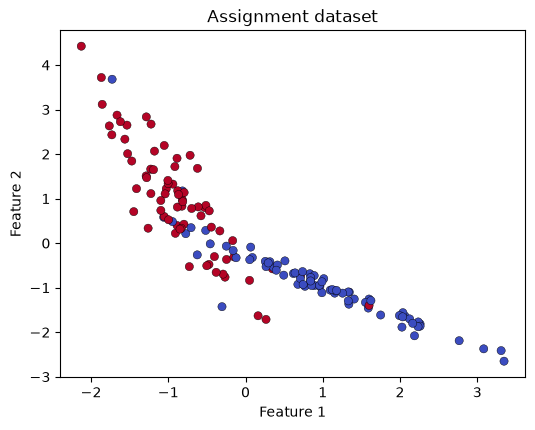

In [2]:
print('X:', X.shape, '| y:', y.shape)
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('Class counts:', np.bincount(y))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', vmin=0, vmax=1,
           edgecolor='black', linewidth=0.3, s=35)
ax.set(xlabel='Feature 1', ylabel='Feature 2', title='Assignment dataset')
plt.show()

**Task 1 — My answer:**  The X ahspe is (150,2), the y shape is (150,), the X train shape is (105,2), the X test shape is (45,2). the rows of X are the samples and the columns of X are the features. The values in y only have 0 and 1 because y only have two classes

## Task 2 — Check a predicted probability and its loss (1 mark)

For **the first test sample** (`X_test[0]`), use the trained weights and bias to calculate:

$$z=w_1x_1+w_2x_2+b,\qquad p=\frac{1}{1+e^{-z}}$$

**(a)** Fill the two lines marked `TODO` to calculate `z` and `p_manual` with NumPy. Compare your probability with the one from `model.predict_proba()`.

**(b)** Run the provided code to calculate the sample's Binary Cross-Entropy loss. Report the loss value and explain whether the model's prediction is good or poor, based on the true label and predicted probability.

**(c)** Write one sentence: Do the manual and sklearn probabilities match (allowing rounding)?

In [14]:
x0 = X_test[0]
y0 = int(y_test[0])
w = model.coef_[0]       # two weights
b = model.intercept_[0] # one bias

# TODO: replace None 
z = x0@w +b

# TODO: replace None 
p_manual = 1/(1+np.exp(-z))

if z is None or p_manual is None:
    print('Task 2: complete z and p_manual before continuing.')
else:
    p_sklearn = probabilities[0]
    p_safe = np.clip(p_manual, 1e-12, 1 - 1e-12)
    sample_loss = -(y0*np.log(p_safe) + (1-y0)*np.log(1-p_safe))
    print('First test row:', x0, 'True label:', y0)
    print('z:', z, 'p_manual:', p_manual, 'p_sklearn:', p_sklearn)
    print('Sample binary cross-entropy:', sample_loss)
    assert np.isclose(p_manual, p_sklearn, atol=1e-8)

First test row: [ 0.315 -0.417] True label: 0
z: -0.7477295759459348 p_manual: 0.3213162159843463 p_sklearn: 0.3213162159843463
Sample binary cross-entropy: 0.38759996827090876


**Task 2 — My answer:** The loss value is 0.38759996827090876. The true label is 0, and the p to class 1 is around 0.32, so it will produce the class 0, which matches the true label 0. Thus the prediction is good. The p manual and p sklearn match. 

## Task 3 — Compare classification thresholds (1 mark)

**(a)** Complete the two `TODO` lines so you get predictions at thresholds **0.5** and **0.7** from the **same trained model**. Do not call `.fit()` again.

**(b)** Run the evaluation cell and report **accuracy**, **false positives (FP)** and **false negatives (FN)** for both thresholds.

**(c)** Explain what changed when the threshold increased from 0.5 to 0.7, and why higher accuracy is **not** guaranteed. You may refer to the actual values you observed.

In [15]:
# TODO: produce 0/1 integer arrays with the specified threshold
def predict_with_threshold(p, threshold):
    p = np.asarray(p)
    return (p >= threshold).astype(int)

pred_05 = predict_with_threshold(probabilities, 0.5)
pred_07 = predict_with_threshold(probabilities, 0.7)

if pred_05 is None or pred_07 is None:
    print('Task 3: complete pred_05 and pred_07 first.')
else:
    for t, predicted in [(0.5, pred_05), (0.7, pred_07)]:
        tn, fp, fn, tp = confusion_matrix(y_test, predicted, labels=[0, 1]).ravel()
        accuracy = accuracy_score(y_test, predicted)
        print(f't={t:.1f}: accuracy={accuracy:.3f}, FP={fp}, FN={fn}, '
              f'predicted class 1={predicted.sum()}')

t=0.5: accuracy=0.867, FP=4, FN=2, predicted class 1=24
t=0.7: accuracy=0.822, FP=1, FN=7, predicted class 1=16


**Task 3 — My answer:** When threshold is 0.5, the accuracy is 0.867, the false positives is 4, the false negatives is 2. When threshold is 0.7, the accuracy is 0.822, the false positives is 1, the false negatives is 7. The accuray drops as the threshold increases from 0.5 to 0.7. Higher threshold drops the flase positive, but also increases the false negative, and increase in the number of false negative over beats the decrease in number of false positive, that's why the model doesn't produce higher accuracy.

## Task 4 — Investigate one mistake (1 mark)

Use a classification threshold of **0.7**. The code below lists the incorrectly classified samples.

Select one incorrectly classified sample from the test set.

1. Report its test row index, true label, predicted probability of Class 1, and predicted label.
2. Is this a **False Positive (FP)** or a **False Negative (FN)**?
3. Would changing the threshold back to **0.5** correct this prediction? Explain using its predicted probability.


In [16]:
predicted = (probabilities >= 0.7).astype(int)
wrong_rows = np.flatnonzero(predicted != y_test)
print('Incorrect test rows:', wrong_rows.tolist())
for i in wrong_rows:
    print(f'row={i:2d}, features={np.round(X_test[i], 2)}, '
          f'actual={y_test[i]}, predicted={predicted[i]}, '
          f'p(class 1)={probabilities[i]:.3f}')

Incorrect test rows: [6, 12, 13, 17, 20, 30, 32, 42]
row= 6, features=[ 0.32 -0.48], actual=1, predicted=0, p(class 1)=0.318
row=12, features=[-0.5  -0.51], actual=1, predicted=0, p(class 1)=0.671
row=13, features=[-0.4 -0.3], actual=1, predicted=0, p(class 1)=0.636
row=17, features=[-0.27 -0.76], actual=1, predicted=0, p(class 1)=0.564
row=20, features=[-0.77  0.21], actual=0, predicted=1, p(class 1)=0.784
row=30, features=[-0.17  0.06], actual=1, predicted=0, p(class 1)=0.544
row=32, features=[ 0.35 -0.58], actual=1, predicted=0, p(class 1)=0.304
row=42, features=[-0.38 -0.66], actual=1, predicted=0, p(class 1)=0.617


**Task 4 — My answer:** row 13, true label is 1, predicted probability of class 1 is 0.636, and the perdicted label is 0. It's a false negative. It would correct the prediction, becuase its probability of class 1 is 0.636, which is greater than 0.5, so it will be predicted as 1. 

## Task 5 — AI assistance and verification (1 mark)

AI tools are allowed for understanding, code suggestions, and debugging. In **2–4 lines**, explain:

1. Which parts (if any) you used AI for. If none, write **No AI used**.
2. **One specific check you performed yourself** (for example, a shape check, the manual probability comparison in Task 2, or the change in FP/FN in Task 3).

A record of every prompt is **not** required. This mark is for a clear, concrete verification statement—not for using AI or avoiding AI.

**Task 5 — My answer:**  I used Claude to check my work after I finish. Claude reported that I made a mistake in task 3's code by using p_manual instead of probabilities in the prediction with threshold. After correction, I ran Claude again to make sure every answer is correct.

### Submission checklist

- [ ] I completed the TODO lines in Tasks 2 and 3.
- [ ] I wrote answers in all five task sections.
- [ ] I ran all cells and kept the outputs visible.
- [ ] I am submitting this `.ipynb` file, **not** the Workshop 05 practice notebook.
- [ ] I saved the completed notebook in `assignment02_Logistic_Regression/` in my GitHub repository.